In [1]:
import dipole
import minimizing
import numpy as np
import matplotlib.pyplot as plt
from scipy import integrate

In [2]:
lambda_qcd = 0.241 #GeV
conv_fmGeV = 5.068 # fm to GeV^-1
d = 0.54 * conv_fmGeV # GeV-1 
A = 197 # 197 for Au beam, 208 for Pb beam
conv_mbGeV2 = 2.56819

def RA(A):
    return (1.12 * A**(1/3) - 0.86*A**(-1/3))*conv_fmGeV # return in GeV^-1

def rhoA(z, bt, A): # Woods-Saxon distribution # GeV-1 
    ra = RA(A)
    n = 3.0/(4.0 * np.pi * RA(A)**3) * 1.0/(1.0 + (np.pi * d/RA(A))**2)
    B = (np.sqrt(bt**2 + z**2) - ra)/d
    rhoA = n / (1 + np.exp(B))
    return rhoA

# Woods-Saxon distribution T_A: rhoA integrated over z
def get_TA(bt, A): 
    TA = integrate.quad(rhoA, -999.0, 999.0, args = (bt, A))
    return TA[0]

def dipA(r, bt, A, Qs02, gamma, e_c, sigma0_2): # dipole nucleus
    sigma0_2 = sigma0_2 * 2.56819 # converted to 1/GeV2
    #n = woods_saxon_norm(A)
    #test = integrate.quad(lambda b: 2.0*np.pi*b*get_TA(b, A), 0, np.inf)
    #assert np.isclose(test[0], 1.0, atol=1e-3), "Thickness function not normalized to 1.0"
    TA = get_TA(bt, A) 
    B = A * TA * (sigma0_2)*((r**2)*(Qs02))**gamma
    C = 1/(r*lambda_qcd) + e_c * np.exp(1)
    N = 1 - np.exp(-B/4 * np.log(C))
    #print(TA)
    return N

In [3]:
#load initial condition parameters
#ic_qs, ic_ec, ic_c2, ic_sigma02 = np.loadtxt("../data/hm2013/mv_param.dat", unpack = True)
ic_qs, ic_ec, ic_c2, ic_sigma02 = np.loadtxt("../data/dipole/posteriorsamples_100_LOmvefit.dat", unpack = True)


In [4]:
from scipy.optimize import fsolve

def qs_func(r, bk_interp, y):
    #x0 = 1.0
    #xbj = 0.00001 # 10⁻5
    #y_int = np.log(x0/x)
    func = bk_interp(y, r) - (1 - np.exp(-1/2))
    return func

def solve_qs(bk_interp, y):
    r_guess = 0.20
    r_solution = fsolve(qs_func, r_guess, args = (bk_interp, y))
    qs_solution = 2/r_solution**2

    if qs_solution < 0 or np.isnan(qs_solution):
        raise ValueError("Nan or negative Qs solution found.")
    
    if bk_interp(y, np.sqrt(2/qs_solution)) > 0.39347 or bk_interp(y, np.sqrt(2/qs_solution)) < 0.39345:
        raise ValueError("Qs solution does not satisfy the condition N(r=√(2/$Q_s^2$), y) ≈ 1 - exp(-1/2).")

    return qs_solution

Reading BK file: ../data/nucleus/ic_197_0.dat
Qs from BK:  [0.85962629]
### y =  0.0
[ 0.16900215  1.0000006  58.53092202  0.999979  ]
Qs from BK:  [1.10817004]
### y =  2.0
[0.57664322 1.0092216  5.69188282 0.60499918]
Qs from BK:  [1.60234123]
### y =  4.0
[1.08591215 0.98598436 0.68631068 0.78784316]
Qs from BK:  [2.50066847]
### y =  6.0
[1.99600083 0.96884691 2.50089237 0.50621616]
Qs from BK:  [4.07709659]
### y =  8.0
[3.518202   0.95386519 3.47830561 0.4540649 ]


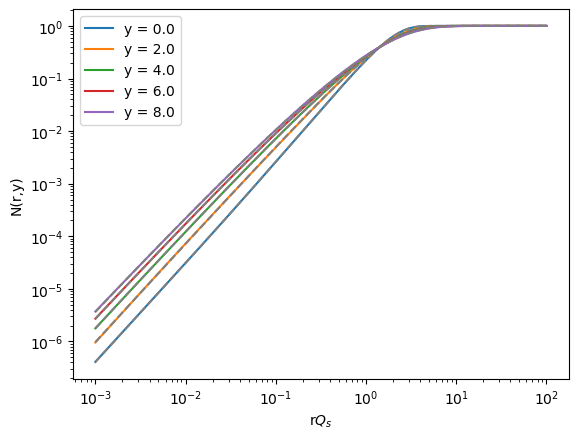

In [9]:
#bk_file = "../data/dipole/initial_run/bk_samplefrommvefit.dat"
#bk_file = '../data/nucleus/posterior/0/ic_197_0.dat'
bk_file = '../data/nucleus/ic_197_0.dat'
#bk_file = "../data/hm2013/mv_bk.dat"
#bk_file = "../data/hm2013/Au/bk/glauber_mv1_0"
BKinterpolator = dipole.BKDipole(bk_file)
#init = [1.0, 0.8, 1.0, 1.0]
init = [1.0, 0.8, 1.0, 0.8]
lbounds = [0.001, 0.1, 1.0/np.exp(1), 0.1]
ubounds = [10.0, 100.0, 100.0, 10.0]
grid_size = 5 # 100
y_max = 8.0
y_array = np.linspace(0, y_max, grid_size)
rqsgrid = np.logspace(-3, 2, 200)
allr = np.logspace(-3,2, 200)
Nyr = lambda yy,rr: BKinterpolator.ln_Nr(yy,rr) # Make interpolator to a callable function
func_qs2 = lambda yy,rr: BKinterpolator.N(yy,rr)
fit_params_array = np.ones((len(y_array), 4))
i = 0
file_params = open("test.dat", "w")
for y in y_array:
    # if i == 0:
    #     initial = init
    # else:
    #     initial = fit_params_array[i-1, :]
    Qs2 = solve_qs(func_qs2, y)
    print("Qs from BK: ", Qs2)
    #print("Check if Qs is correct: ", func_qs2(y, np.sqrt(2/Qs2))) 
    r = rqsgrid/np.sqrt(Qs2)
    #print('r=',r)
    minimizer = minimizing.MyMinimizer(Nyr, y, r, init, lbounds = lbounds, ubounds = ubounds)
    out = minimizer.fit_ls()
    fit_params = out.x
    fit_params_array[i, :] = fit_params
    
    fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    plt.plot(rqsgrid, np.exp(fit_func), '-', label='y = '+str(np.round(y,3)))
    plt.plot(rqsgrid, np.exp(Nyr(y,r)), '--', color = 'gray')
    plt.xscale('log')
    plt.yscale('log')
    plt.legend()
    plt.xlabel('r$Q_s$')
    plt.ylabel('N(r,y)')
    # if y == 0 or y == 0.12:
    #     fit_params_array[i, :] = [ic_qs[0], 1.0, ic_ec[0], 1.0]
    #     fit_params_array[i, 0] = 197 * get_TA(0, A) * ic_sigma02[0] * conv_mbGeV2 * ic_qs[0]
    #fit_func = minimizer.parametrization(fit_params[0], fit_params[1], fit_params[2], fit_params[3])
    print('### y = ', np.round(y,3))
    print(fit_params_array[i, :] )
    # if y > 1:
    #init = fit_params
    i += 1

with file_params:
    file_params.write("# Parameter file of fit of dipole from {}".format(bk_file) + "\n")
    file_params.write("# y ranges from 0 to {} in {} steps".format(y_max, grid_size) + "\n")
    file_params.write("# Columns: y, Qs2, gamma, ec, p" + "\n")
    for j in range(len(y_array)):
        file_params.write("{: .6e} {: .6e} {: .6e} {: .6e} {: .6e}\n".format(y_array[j], fit_params_array[j,0], fit_params_array[j,1], fit_params_array[j,2], fit_params_array[j,3]))

## Get Fourier transform

In [8]:
interpolator = BKinterpolator.ReadBKDipole()[0]
from hankel import HankelTransform

def S(y,k):

    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = interpolator(y, r) #minimizer.Ff(r, fit_params)
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

def log_S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params[0], fit_params[1], fit_params[2], fit_params[3])
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [np.log10(ht.transform(func_to_ht, i, ret_err=False)) for i in k]
    return np.array(sp_values)

def S2(k, fit_params):
    ht = HankelTransform(nu = 0, N = 1000, h = 0.001)

    def func_to_ht(r):
        f = minimizer.Ff(r, fit_params[0], fit_params[1], fit_params[2], fit_params[3])
        f = np.nan_to_num(f, nan=1.0)
        return 1 - f

    sp_values = [ht.transform(func_to_ht, i, ret_err=False) for i in k]
    return np.array(sp_values)

Reading BK file: ../data/nucleus/ic_197_0.dat


[1.00000000e-02 1.20679264e-02 1.45634848e-02 1.75751062e-02
 2.12095089e-02 2.55954792e-02 3.08884360e-02 3.72759372e-02
 4.49843267e-02 5.42867544e-02 6.55128557e-02 7.90604321e-02
 9.54095476e-02 1.15139540e-01 1.38949549e-01 1.67683294e-01
 2.02358965e-01 2.44205309e-01 2.94705170e-01 3.55648031e-01
 4.29193426e-01 5.17947468e-01 6.25055193e-01 7.54312006e-01
 9.10298178e-01 1.09854114e+00 1.32571137e+00 1.59985872e+00
 1.93069773e+00 2.32995181e+00 2.81176870e+00 3.39322177e+00
 4.09491506e+00 4.94171336e+00 5.96362332e+00 7.19685673e+00
 8.68511374e+00 1.04811313e+01 1.26485522e+01 1.52641797e+01
 1.84206997e+01 2.22299648e+01 2.68269580e+01 3.23745754e+01
 3.90693994e+01 4.71486636e+01 5.68986603e+01 6.86648845e+01
 8.28642773e+01 1.00000000e+02]


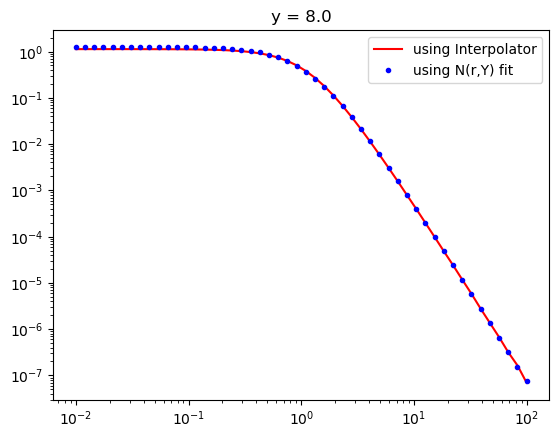

In [9]:
fit_params = fit_params_array[grid_size-1] # last rapidity
k = np.logspace(-2, 2, 50)
print(k)
Sk = S(y_max,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using N(r,Y) fit', color='blue')
plt.title(f'y = {y_max}')
plt.legend()
plt.xscale('log')
plt.yscale('log')

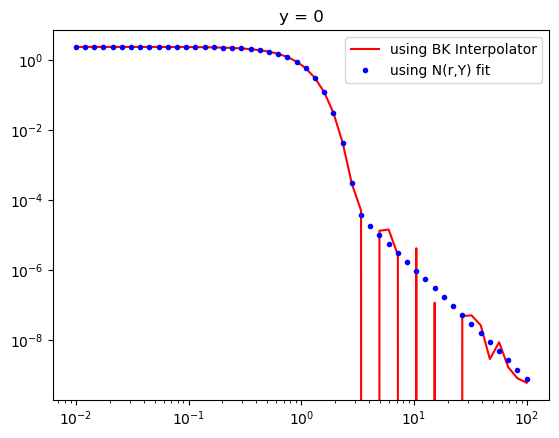

In [10]:
fit_params = fit_params_array[0]
#print("Fit params at y=0: ", fit_params)
#fit_params = [0.11968468, 0.6, 4.77656673, 1.5]
k = np.logspace(-2, 2, 50)
Sk = S(0,k)
Sk2 = log_S2(k, fit_params)
plt.plot(k, Sk, label='using BK Interpolator', color='red')
plt.plot(k, 10**Sk2, '.', label = 'using N(r,Y) fit', color='blue')
plt.title('y = 0')
plt.legend()
plt.xscale('log')
plt.yscale('log')

In [11]:
Sk

array([ 2.31191824e+00,  2.32669582e+00,  2.33098000e+00,  2.32760432e+00,
        2.32813832e+00,  2.32721118e+00,  2.32680637e+00,  2.32524189e+00,
        2.32355117e+00,  2.32156031e+00,  2.31763505e+00,  2.31215460e+00,
        2.30455341e+00,  2.29347617e+00,  2.27736122e+00,  2.25409403e+00,
        2.22066044e+00,  2.17282051e+00,  2.10500151e+00,  2.01001777e+00,
        1.87924263e+00,  1.70387963e+00,  1.47731589e+00,  1.20010770e+00,
        8.86682152e-01,  5.70580750e-01,  3.00297773e-01,  1.18024605e-01,
        3.04138379e-02,  4.30560616e-03,  2.89156264e-04,  5.01029215e-05,
       -1.25098679e-05,  1.32619702e-05,  1.43129062e-05,  2.67878498e-06,
       -9.54631622e-07,  4.19969847e-06, -5.07947248e-07,  1.16838984e-07,
       -1.41851510e-08, -3.67949803e-08,  4.84331367e-08,  5.11065242e-08,
        2.67047301e-08,  2.87978281e-09,  8.71877329e-09,  1.67984374e-09,
        8.14447977e-10,  6.03683055e-10])

[ 0.36395255  0.36506135  0.36673931  0.36767626  0.36767649  0.36728387
  0.36702455  0.36699993  0.36703842  0.36701607  0.36694655  0.36687231
  0.36679461  0.36669941  0.36658255  0.36644232  0.36627364  0.36607034
  0.36582548  0.36553054  0.3651753   0.3647474   0.36423199  0.36361119
  0.36286342  0.36196274  0.36087786  0.35957113  0.35799716  0.35610132
  0.35381777  0.35106723  0.3477542   0.34376366  0.33895705  0.33316749
  0.32619397  0.31779438  0.30767712  0.29549093  0.28081275  0.26313303
  0.24183804  0.21618858  0.18529437  0.14808316  0.10326363  0.04928062
 -0.01573856 -0.09404881 -0.18836481 -0.30195403 -0.43874768 -0.60347225
 -0.80180272 -1.04053429 -1.32775323 -1.67293259 -2.08666529 -2.57883854
 -3.14989817 -3.75463096 -4.23696147 -4.49458383 -4.64967574 -4.78515558
 -4.91662511 -5.04603228 -5.17392731 -5.3006673  -5.42651791 -5.55168393
 -5.67632742 -5.80057968 -5.92454936 -6.04832836 -6.17199613 -6.29562287
 -6.41927204 -6.54300227 -6.66686886 -6.79092498 -6

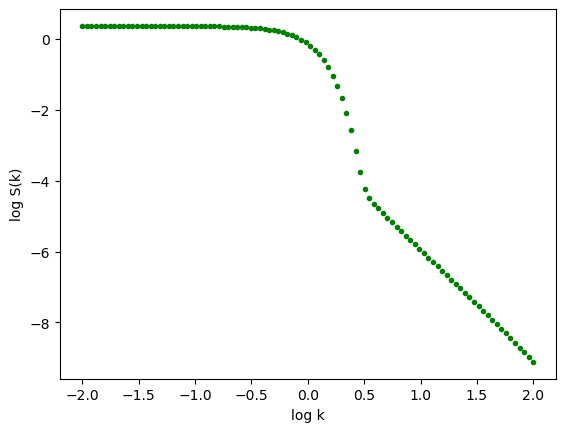

In [12]:
import pandas as pd
k_grid_size = 100#500
log_k_grid = np.linspace(-2, 2, k_grid_size)
log_Sk2 = log_S2(10**log_k_grid, fit_params)
plt.plot(log_k_grid, log_Sk2, '.',label='using fit at y=0.0', color='green')
plt.xlabel('log k')
plt.ylabel('log S(k)')
print(log_Sk2)

In [13]:
y_array_repeat = np.repeat(y_array, k_grid_size)
log_k_min = -2
log_k_max = 2
log_k_all = []
log_Sk2_all = []



for i in range(len(y_array)):
    fit_params = fit_params_array[i, :]
    log_k_grid = np.linspace(log_k_min, log_k_max, k_grid_size)
    log_Sk2 = log_S2(10**log_k_grid, fit_params)
    log_k_all.extend(log_k_grid)
    log_Sk2_all.extend(log_Sk2)

data = {'y': y_array_repeat, 'log10_k':log_k_all, 'log10_S(k)':log_Sk2_all}
df = pd.DataFrame(data)
print(np.shape(y_array_repeat))
print(np.shape(log_k_all))
print(np.shape(log_Sk2_all))

(500,)
(500,)
(500,)


In [14]:
print(fit_params_array)

[[ 0.16900215  1.0000006  58.53092202  0.999979  ]
 [ 0.57664322  1.0092216   5.69188282  0.60499918]
 [ 1.08591215  0.98598436  0.68631068  0.78784316]
 [ 1.99600083  0.96884691  2.50089237  0.50621616]
 [ 3.518202    0.95386519  3.47830561  0.4540649 ]]


Text(0.5, 0, 'y')

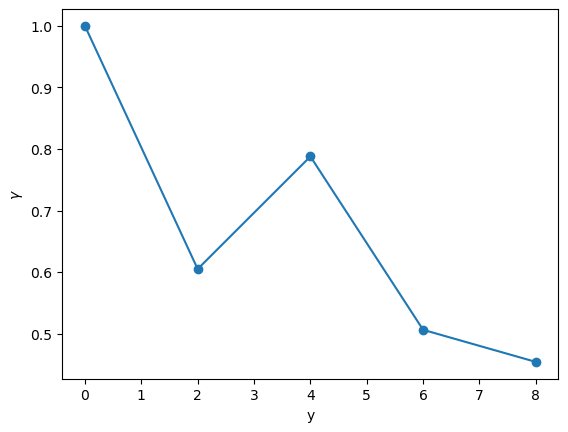

In [15]:
plt.plot(y_array, fit_params_array[:,3], '-o')
plt.ylabel('$\gamma$')
plt.xlabel('y')

In [16]:
# csv_file = '../data/hm2013/SK_data.csv'
# comments = ['## Generated from BK dipole with initial condition (arXiv: 1309.6963): MV model, Q_s0^2 = 0.104 GeV^2, \gamma = 1, coefficient of E inside Log is 1',
#                    '## Fitted to file {0}'.format(bk_file),
#                    '## Note definition of log S(k): log_S(k) = log10 S(k) = log10 [ \int r dr J0(k r) (1 - N(r)) ]',
#                    '## log10 k grid ranges from {0} to {1} with {2} points'.format(log_k_min, log_k_max, k_grid_size),
#                    '## y grid ranges from 0 to {0} with {1} points'.format(y_max, grid_size),]

# save_files = True
# with open(csv_file, 'w') as f:
#     for comment in comments:
#         f.write(comment + '\n')
# df.to_csv(csv_file, index=False, sep = ' ', columns=['y', 'log10_k', 'log10_S(k)'], mode='a', float_format='%.6e') if save_files else None

In [17]:
# import difflib

# file1 = "/home/caaucasu/sidis_fit/data/hm2013/2Dft_dipole_orig.csv"
# file2 = "/home/caaucasu/sidis_fit/data/hm2013/SK_data.csv"
# # Source - https://stackoverflow.com/a/19007888
# # Posted by Robᵩ, modified by community. See post 'Timeline' for change history
# # Retrieved 2026-05-15, License - CC BY-SA 4.0

# with open("/home/caaucasu/sidis_fit/data/hm2013/2Dft_dipole_orig.csv", 'r') as file1:
#     with open("/home/caaucasu/sidis_fit/data/hm2013/SK_data.csv", 'r') as file2:
#         same = set(file1).difference(file2)

# same.discard('\n')

# with open('some_output_file.txt', 'w') as file_out:
#     for line in same:
#         file_out.write(line)

